113221023 碩二 陳宗毅

**MobileNetV2**

In [76]:
import os
import pathlib
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, InceptionV3
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [77]:
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224
SEED = 123
FEATURE_EPOCHS = 10
FINE_TUNE_EPOCHS = 15
#FINE_TUNE_AT = 100

In [78]:
data_tar = tf.keras.utils.get_file(
    'flower_photos.tgz',
    'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz',
    untar=True
)
# get_file + untar=True 回傳的通常是解壓後的資料夾路徑 (有時會多一層)
data_root = pathlib.Path(data_tar)
# 如果上層是 file without nested folder, adjust:
if data_root.is_dir() and any(data_root.iterdir()):
    # sometimes data_tar points to .../flower_photos (folder), sometimes to .../flower_photos/flower_photos
    # check if it contains subfolder 'flower_photos'
    nested = data_root / 'flower_photos'
    if nested.exists():
        data_dir = str(nested)
    else:
        data_dir = str(data_root)
else:
    raise RuntimeError("找不到資料資料夾，請檢查下載與解壓路徑。")

print("Using data directory:", data_dir)

Using data directory: /root/.keras/datasets/flower_photos_extracted/flower_photos


In [79]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,  # MobileNetV2 expects inputs preprocessed this way
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2  # split 20% for validation
)

In [80]:
train_generator = train_datagen.flow_from_directory(
    data_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=SEED,
    shuffle=True
)

validation_generator = train_datagen.flow_from_directory(
    data_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=SEED,
    shuffle=False
)

class_names = list(train_generator.class_indices.keys())
num_classes = len(class_names)
print("Classes:", class_names)

Found 2939 images belonging to 5 classes.
Found 731 images belonging to 5 classes.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [81]:
base_model = MobileNetV2(weights='imagenet', include_top=False,
                         input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
base_model.trainable = False

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7),
    #tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    #tf.keras.callbacks.ModelCheckpoint('best.h5', save_best_only=True)
]

inputs = tf.keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(512, activation='relu')(x)
x = layers.Dropout(0.5)(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)
model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)


model.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_25 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_14     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_113         │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_114         │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,053,637 (11.65 MB)

 Trainable params: 792,069 (3.02 MB)

 Non-trainable params: 2,261,568 (8.63 MB)

In [82]:
# Train (feature extraction)

history_feat = model.fit(
    train_generator,
    epochs=FEATURE_EPOCHS,
    validation_data=validation_generator,
    callbacks=callbacks
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 132s 1s/step - accuracy: 0.6139 - loss: 1.2745 - val_accuracy: 0.8140 - val_loss: 0.7700 - learning_rate: 0.0010
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step - accuracy: 0.8195 - loss: 0.8284 - val_accuracy: 0.8659 - val_loss: 0.7081 - learning_rate: 0.0010
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.8452 - loss: 0.7773 - val_accuracy: 0.8728 - val_loss: 0.6976 - learning_rate: 0.0010
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - accuracy: 0.8664 - loss: 0.7226 - val_accuracy: 0.8714 - val_loss: 0.6808 - learning_rate: 0.0010
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 117s 1s/step - accuracy: 0.8852 - loss: 0.6868 - val_accuracy: 0.8714 - val_loss: 0.6646 - learning_rate: 0.0010
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 116s 1s/step - accuracy: 0.8839 - loss: 0.6768 - val_accuracy: 0.8892 - val_loss: 0.6544 - learning_rate: 0.0010
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 116s 1s/step - accuracy: 0.9016 - loss: 0.6332 - val_acc

In [83]:
# fine-tune
base_model.trainable = True
fine_tune_at = int(len(base_model.layers) * 0.6)
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False
for layer in base_model.layers[fine_tune_at:]:
    layer.trainable = True



# recompile with lower lr
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

model.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_25 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_14     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_113         │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_114         │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,053,637 (11.65 MB)

 Trainable params: 2,751,237 (10.50 MB)

 Non-trainable params: 302,400 (1.15 MB)

In [84]:
total_epochs = FEATURE_EPOCHS + FINE_TUNE_EPOCHS
history_fine = model.fit(
    train_generator,
    epochs=total_epochs,
    initial_epoch=history_feat.epoch[-1] + 1 if history_feat.epoch else FEATURE_EPOCHS,
    validation_data=validation_generator,
    callbacks=callbacks
)

Epoch 11/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 188s 2s/step - accuracy: 0.8473 - loss: 0.7513 - val_accuracy: 0.8810 - val_loss: 0.6703 - learning_rate: 1.0000e-05
Epoch 12/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 195s 2s/step - accuracy: 0.8681 - loss: 0.7064 - val_accuracy: 0.8824 - val_loss: 0.6752 - learning_rate: 1.0000e-05
Epoch 13/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 175s 2s/step - accuracy: 0.8821 - loss: 0.6717 - val_accuracy: 0.8728 - val_loss: 0.6803 - learning_rate: 1.0000e-05
Epoch 14/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 171s 2s/step - accuracy: 0.8974 - loss: 0.6557 - val_accuracy: 0.8906 - val_loss: 0.6593 - learning_rate: 1.0000e-05
Epoch 15/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 177s 2s/step - accuracy: 0.9150 - loss: 0.6196 - val_accuracy: 0.8919 - val_loss: 0.6596 - learning_rate: 1.0000e-05
Epoch 16/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 174s 2s/step - accuracy: 0.9156 - loss: 0.6080 - val_accuracy: 0.8988 - val_loss: 0.6574 - learning_rate: 1.0000e-05
Epoch 17/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 170s 2s/step - accuracy: 

In [85]:
val_loss, val_acc = model.evaluate(validation_generator)
print(f"Validation loss: {val_loss:.4f}, Validation accuracy: {val_acc:.4f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.9143 - loss: 0.6018  
Validation loss: 0.6296, Validation accuracy: 0.9056


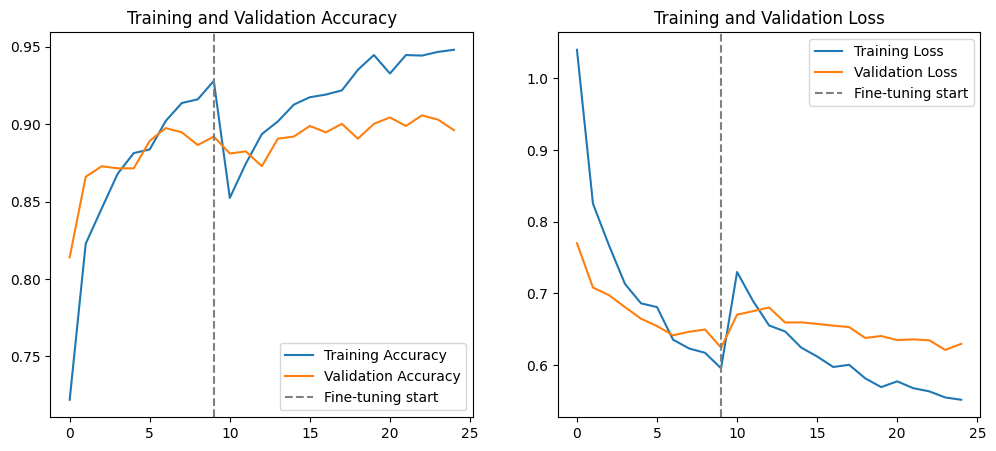

In [86]:
import matplotlib.pyplot as plt

# 取出兩階段訓練的紀錄
acc = history_feat.history['accuracy'] + history_fine.history['accuracy']
val_acc = history_feat.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history_feat.history['loss'] + history_fine.history['loss']
val_loss = history_feat.history['val_loss'] + history_fine.history['val_loss']

# 建立 epoch 軸
epochs_feat = range(len(history_feat.history['accuracy']))
epochs_fine = range(len(history_feat.history['accuracy']), len(acc))

plt.figure(figsize=(12, 5))

# --- Accuracy 曲線 ---
plt.subplot(1, 2, 1)
plt.plot(range(len(acc)), acc, label='Training Accuracy')
plt.plot(range(len(val_acc)), val_acc, label='Validation Accuracy')
plt.axvline(x=len(history_feat.history['accuracy']) - 1, color='gray', linestyle='--', label='Fine-tuning start')
plt.title('Training and Validation Accuracy')
plt.legend(loc='lower right')

# --- Loss 曲線 ---
plt.subplot(1, 2, 2)
plt.plot(range(len(loss)), loss, label='Training Loss')
plt.plot(range(len(val_loss)), val_loss, label='Validation Loss')
plt.axvline(x=len(history_feat.history['accuracy']) - 1, color='gray', linestyle='--', label='Fine-tuning start')
plt.title('Training and Validation Loss')
plt.legend(loc='upper right')

plt.show()


**InceptionV3**

In [87]:
base_model = InceptionV3(weights='imagenet', include_top=False,
                         input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
base_model.trainable = False

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    #tf.keras.callbacks.ModelCheckpoint('best.h5', save_best_only=True)
]

inputs = tf.keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(512, activation='relu')(x)
x = layers.Dropout(0.5)(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)
model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)


model.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_27 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_15     │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_209         │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_210         │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,994,725 (87.72 MB)

 Trainable params: 1,186,821 (4.53 MB)

 Non-trainable params: 21,807,904 (83.19 MB)

In [88]:
# Train (feature extraction)

history_feat = model.fit(
    train_generator,
    epochs=FEATURE_EPOCHS,
    validation_data=validation_generator,
    callbacks=callbacks
)


Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 316s 3s/step - accuracy: 0.6295 - loss: 1.2151 - val_accuracy: 0.8057 - val_loss: 0.8350 - learning_rate: 0.0010
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 301s 3s/step - accuracy: 0.7952 - loss: 0.8702 - val_accuracy: 0.8276 - val_loss: 0.7287 - learning_rate: 0.0010
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 307s 3s/step - accuracy: 0.8374 - loss: 0.7893 - val_accuracy: 0.8372 - val_loss: 0.7330 - learning_rate: 0.0010
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 307s 3s/step - accuracy: 0.8273 - loss: 0.7820 - val_accuracy: 0.8386 - val_loss: 0.7473 - learning_rate: 0.0010
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 307s 3s/step - accuracy: 0.8448 - loss: 0.7407 - val_accuracy: 0.8454 - val_loss: 0.7305 - learning_rate: 0.0010
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 324s 4s/step - accuracy: 0.8728 - loss: 0.6997 - val_accuracy: 0.8482 - val_loss: 0.6964 - learning_rate: 5.0000e-04
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 303s 3s/step - accuracy: 0.8828 - loss: 0.6646 - val

In [89]:
# fine-tune
base_model.trainable = True
fine_tune_at = int(len(base_model.layers) * 0.6)
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False
for layer in base_model.layers[fine_tune_at:]:
    layer.trainable = True



# recompile with lower lr
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

model.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_27 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_15     │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_209         │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_210         │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,994,725 (87.72 MB)

 Trainable params: 16,502,021 (62.95 MB)

 Non-trainable params: 6,492,704 (24.77 MB)

In [90]:
total_epochs = FEATURE_EPOCHS + FINE_TUNE_EPOCHS
history_fine = model.fit(
    train_generator,
    epochs=total_epochs,
    initial_epoch=history_feat.epoch[-1] + 1 if history_feat.epoch else FEATURE_EPOCHS,
    validation_data=validation_generator,
    callbacks=callbacks
)

Epoch 11/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 497s 5s/step - accuracy: 0.7444 - loss: 0.9291 - val_accuracy: 0.8523 - val_loss: 0.7401 - learning_rate: 1.0000e-05
Epoch 12/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 479s 5s/step - accuracy: 0.8192 - loss: 0.7727 - val_accuracy: 0.8605 - val_loss: 0.7445 - learning_rate: 1.0000e-05
Epoch 13/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 477s 5s/step - accuracy: 0.8392 - loss: 0.7492 - val_accuracy: 0.8577 - val_loss: 0.7376 - learning_rate: 1.0000e-05
Epoch 14/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 473s 5s/step - accuracy: 0.8550 - loss: 0.7233 - val_accuracy: 0.8550 - val_loss: 0.7291 - learning_rate: 1.0000e-05
Epoch 15/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 475s 5s/step - accuracy: 0.8705 - loss: 0.6860 - val_accuracy: 0.8372 - val_loss: 0.7366 - learning_rate: 1.0000e-05
Epoch 16/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 478s 5s/step - accuracy: 0.8898 - loss: 0.6706 - val_accuracy: 0.8659 - val_loss: 0.7120 - learning_rate: 1.0000e-05
Epoch 17/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 498s 5s/step - accuracy: 

KeyboardInterrupt: 

In [91]:
val_loss, val_acc = model.evaluate(validation_generator)
print(f"Validation loss: {val_loss:.4f}, Validation accuracy: {val_acc:.4f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 68s 3s/step - accuracy: 0.8948 - loss: 0.6660
Validation loss: 0.7002, Validation accuracy: 0.8837


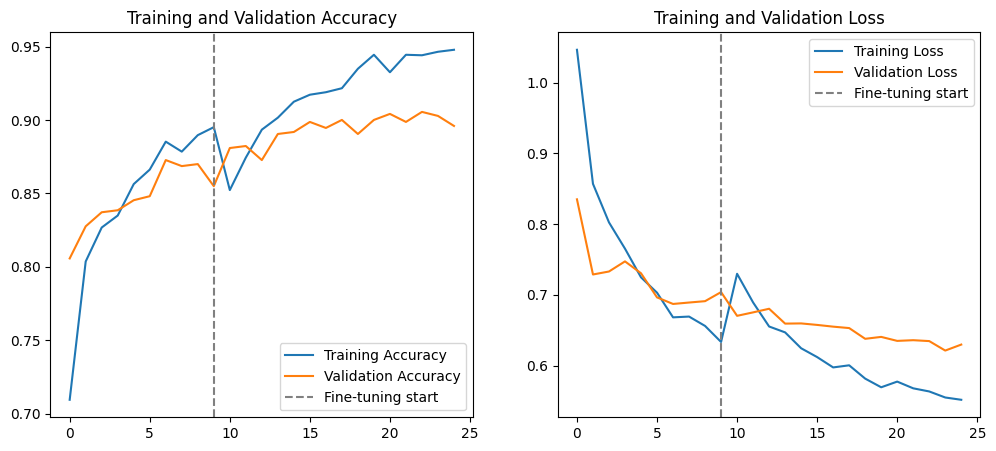

In [92]:
import matplotlib.pyplot as plt

# 取出兩階段訓練的紀錄
acc = history_feat.history['accuracy'] + history_fine.history['accuracy']
val_acc = history_feat.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history_feat.history['loss'] + history_fine.history['loss']
val_loss = history_feat.history['val_loss'] + history_fine.history['val_loss']

# 建立 epoch 軸
epochs_feat = range(len(history_feat.history['accuracy']))
epochs_fine = range(len(history_feat.history['accuracy']), len(acc))

plt.figure(figsize=(12, 5))

# --- Accuracy 曲線 ---
plt.subplot(1, 2, 1)
plt.plot(range(len(acc)), acc, label='Training Accuracy')
plt.plot(range(len(val_acc)), val_acc, label='Validation Accuracy')
plt.axvline(x=len(history_feat.history['accuracy']) - 1, color='gray', linestyle='--', label='Fine-tuning start')
plt.title('Training and Validation Accuracy')
plt.legend(loc='lower right')

# --- Loss 曲線 ---
plt.subplot(1, 2, 2)
plt.plot(range(len(loss)), loss, label='Training Loss')
plt.plot(range(len(val_loss)), val_loss, label='Validation Loss')
plt.axvline(x=len(history_feat.history['accuracy']) - 1, color='gray', linestyle='--', label='Fine-tuning start')
plt.title('Training and Validation Loss')
plt.legend(loc='upper right')

plt.show()


# **模型比較**

**MobileNetV2:**

Train accuracy: 0.9416

Validation accuracy: 0.9056

**InceptionV3**

Train accuracy: 0.9218

Validation accuracy: 0.8837


訓練過程中，對每個epoch，InceptionV3需要的時間較長，結果不理想，需要更多修改。